In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv(r"/content/recover_synthetic_mitumba_traders_5000_low_amounts.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nRandom 5 records:")
display(df.sample(min(5, len(df)), random_state=42))

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (5000, 25)

Column names:
['age_years', 'full_name_synthetic', 'business_type', 'market_area', 'stall_type', 'years_in_business', 'stall_arrangement', 'operating_days_per_week', 'operating_hours_per_day', 'employees_or_assistants', 'average_weekly_sales_kes', 'estimated_monthly_sales_kes', 'estimated_monthly_gross_profit_kes', 'estimated_monthly_net_profit_kes', 'current_stock_value_kes', 'typical_stock_value_kes', 'equipment_value_kes', 'monthly_rent_kes', 'affordable_insurance_premium_kes', 'preferred_cover', 'preferred_payment_frequency', 'preferred_contact_channel', 'previous_loss_type', 'previous_loss_date', 'previous_loss_amount_kes']

First 5 rows:


,age_years,full_name_synthetic,business_type,market_area,stall_type,years_in_business,stall_arrangement,operating_days_per_week,operating_hours_per_day,employees_or_assistants,...,typical_stock_value_kes,equipment_value_kes,monthly_rent_kes,affordable_insurance_premium_kes,preferred_cover,preferred_payment_frequency,preferred_contact_channel,previous_loss_type,previous_loss_date,previous_loss_amount_kes
0,50,Achieng Mwangi,Shoes,Kangemi Market,Enclosed stall/shop,10,Rents stall,5,10,2,...,5000,2600,1850,95,Theft,Monthly,USSD,Theft,9/18/2019,400
1,38,Wanjiku Njoroge,Bags,Toi Market,Open-air display,4,Shares stall,7,8,2,...,2600,750,800,45,Fire,Monthly,Mobile app,NaN,NaN,800
2,54,Atieno Muthama,Mitumba clothes,Toi Market,Open-air display,16,Rents stall,7,9,0,...,8700,1300,800,15,Fire and theft,Monthly,USSD,NaN,NaN,3200
3,47,Njeri Mutiso,Mitumba clothes,Kisumu Kibuye Market,Enclosed stall/shop,19,Rents stall,5,9,0,...,8200,1200,1450,40,Fire,Monthly,USSD,NaN,NaN,2300
4,27,Akinyi Munyua,Shoes,Kawangware Market,Shared stall,2,Rents stall,5,12,1,...,7000,3050,350,30,Theft,Weekly,USSD,NaN,NaN,1200



Random 5 records:


,age_years,full_name_synthetic,business_type,market_area,stall_type,years_in_business,stall_arrangement,operating_days_per_week,operating_hours_per_day,employees_or_assistants,...,typical_stock_value_kes,equipment_value_kes,monthly_rent_kes,affordable_insurance_premium_kes,preferred_cover,preferred_payment_frequency,preferred_contact_channel,previous_loss_type,previous_loss_date,previous_loss_amount_kes
1501,62,Wanjala Kariuki,Mitumba clothes,Kangemi Market,Enclosed stall/shop,1,Shares stall,6,12,2,...,6100,2050,1550,15,Fire and theft,Monthly,USSD,NaN,NaN,3600
2586,35,Wekesa Otieno,Bags,Toi Market,Open-air display,17,Shares stall,6,12,0,...,3800,1750,450,35,Fire,Monthly,Mobile app,NaN,NaN,1800
2653,48,Moraa Auma,Mitumba clothes,Gikomba Market,Open-air display,26,Shares stall,6,9,0,...,6400,1100,950,45,Combined,Daily,USSD,NaN,NaN,1300
1055,46,Kilonzo Kiplagat,Mitumba clothes,Kakamega Market,Open-air display,5,Shares stall,7,12,1,...,2800,1650,500,20,Fire,Weekly,USSD,NaN,NaN,700
705,42,Wekesa Mutua,Mitumba clothes,Ruiru Market,Shared stall,16,Rents stall,5,8,0,...,4300,2600,400,35,Fire and theft,Weekly,Insurance agent,NaN,NaN,2200



Data types:
age_years                              int64
full_name_synthetic                   object
business_type                         object
market_area                           object
stall_type                            object
years_in_business                      int64
stall_arrangement                     object
operating_days_per_week                int64
operating_hours_per_day                int64
employees_or_assistants                int64
average_weekly_sales_kes               int64
estimated_monthly_sales_kes            int64
estimated_monthly_gross_profit_kes     int64
estimated_monthly_net_profit_kes       int64
current_stock_value_kes                int64
typical_stock_value_kes                int64
equipment_value_kes                    int64
monthly_rent_kes                       int64
affordable_insurance_premium_kes       int64
preferred_cover                       object
preferred_payment_frequency           object
preferred_contact_channel             obje

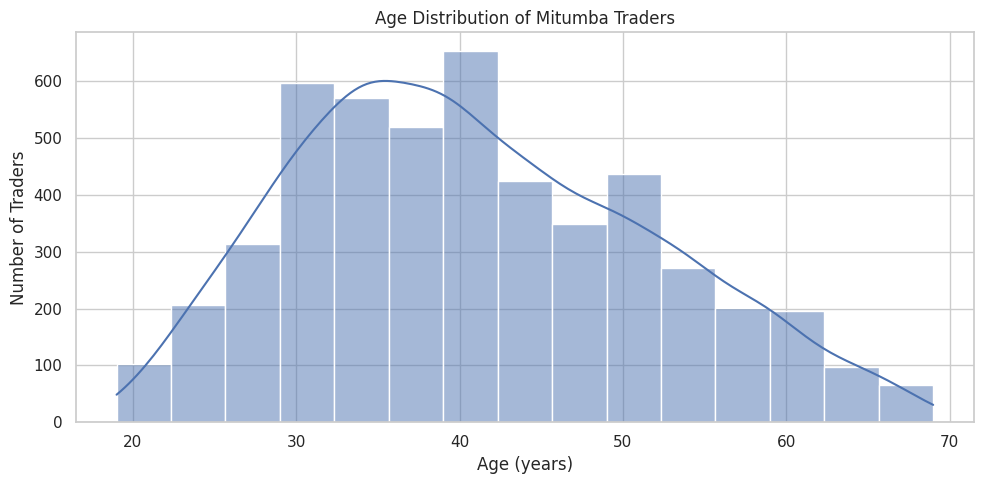

In [9]:
#Age distribution

if "age_years" in df.columns:
    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x="age_years",
        bins=15,
        kde=True
    )

    plt.title("Age Distribution of Mitumba Traders")
    plt.xlabel("Age (years)")
    plt.ylabel("Number of Traders")
    plt.tight_layout()
    plt.show()

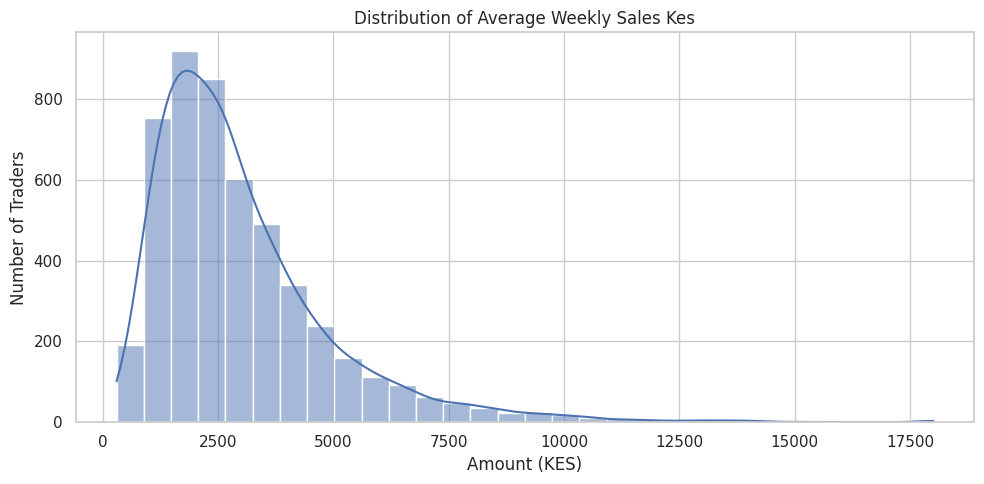

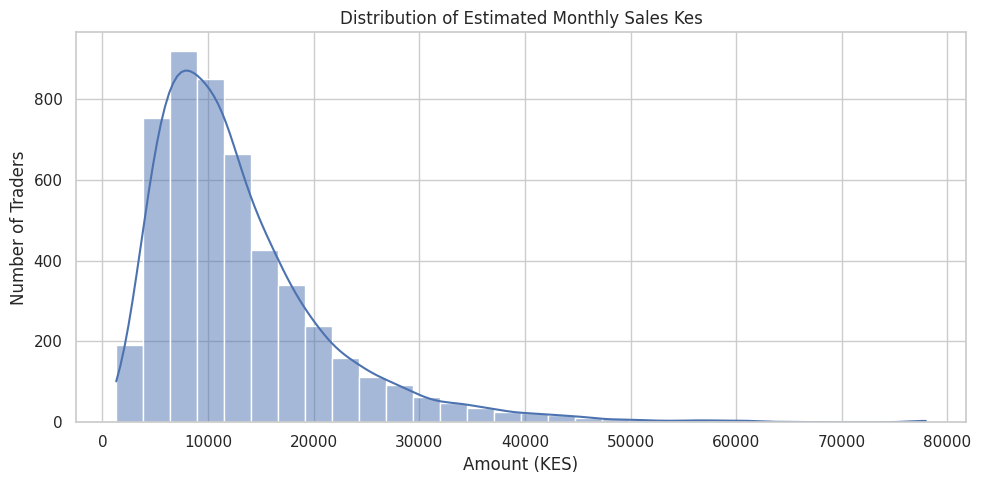

In [10]:
#Distribution of sales

sales_columns = [
    "average_weekly_sales_kes",
    "estimated_monthly_sales_kes"
]

for col in sales_columns:
    if col in df.columns:
        plt.figure(figsize=(10, 5))

        sns.histplot(
            data=df,
            x=col,
            bins=30,
            kde=True
        )

        plt.title(f"Distribution of {col.replace('_', ' ').title()}")
        plt.xlabel("Amount (KES)")
        plt.ylabel("Number of Traders")
        plt.tight_layout()
        plt.show()

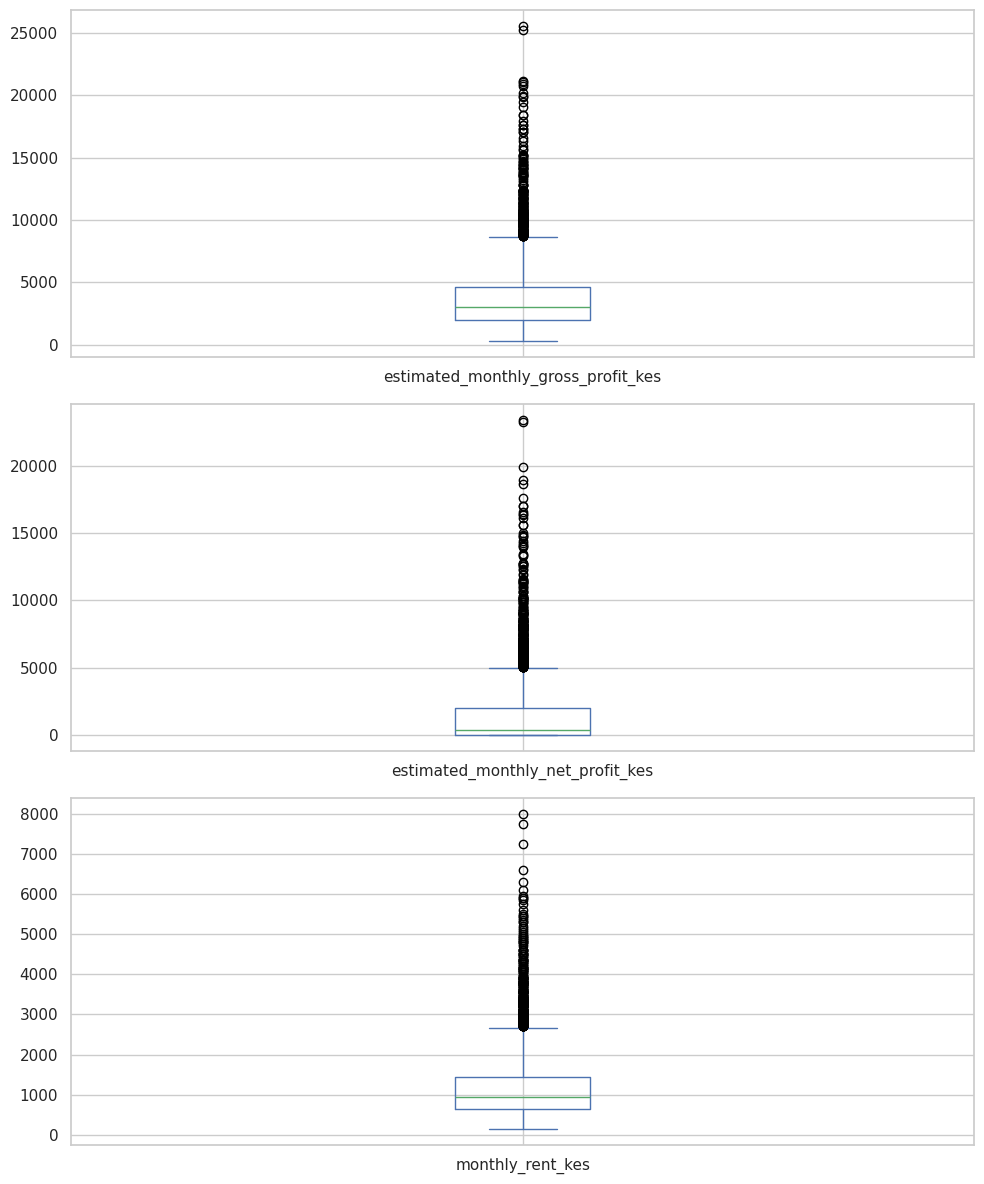

In [11]:
#  Compare financial measures

financial_columns = [
    "estimated_monthly_gross_profit_kes",
    "estimated_monthly_net_profit_kes",
    "monthly_rent_kes"
]

available_financial = [
    col for col in financial_columns if col in df.columns
]

if available_financial:
    df[available_financial].plot(
        kind="box",
        subplots=True,
        layout=(len(available_financial), 1),
        figsize=(10, 4 * len(available_financial)),
        sharex=False,
        sharey=False
    )

    plt.tight_layout()
    plt.show()

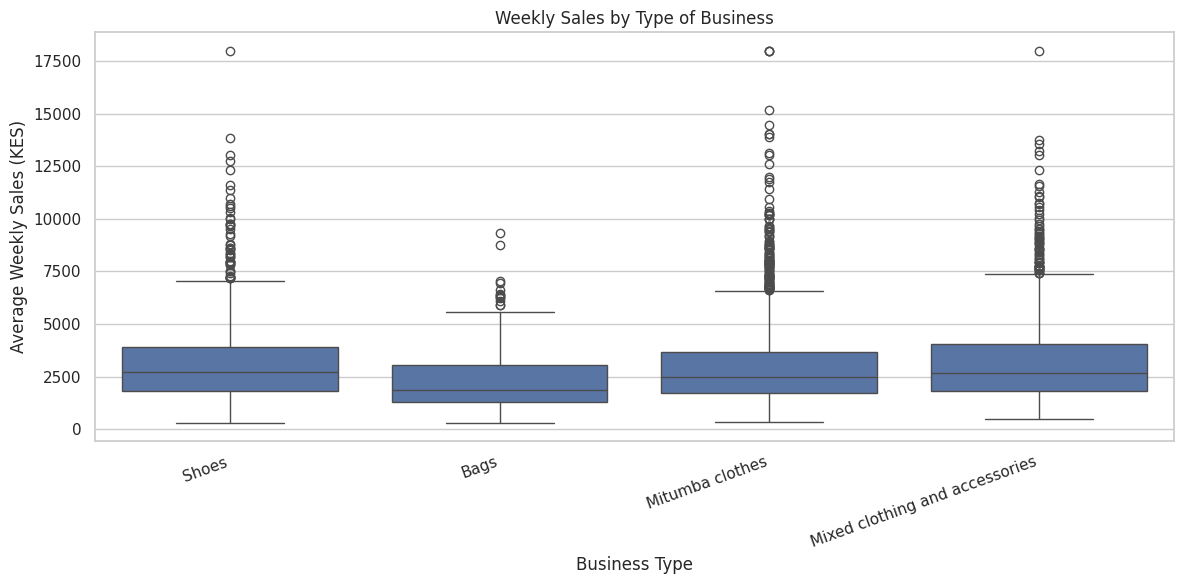

In [12]:
# Cell 8: Weekly sales by business type

if {"business_type", "average_weekly_sales_kes"}.issubset(df.columns):

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=df,
        x="business_type",
        y="average_weekly_sales_kes"
    )

    plt.title("Weekly Sales by Type of Business")
    plt.xlabel("Business Type")
    plt.ylabel("Average Weekly Sales (KES)")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

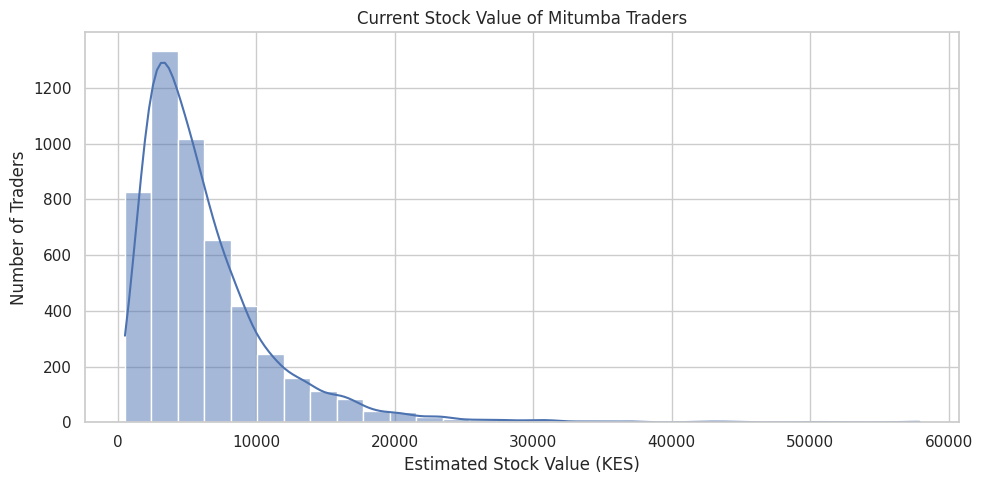

Stock value summary:
count     5000.000000
mean      6204.640000
std       4876.578173
min        500.000000
25%       3000.000000
50%       4900.000000
75%       7800.000000
90%      12000.000000
max      57900.000000
Name: current_stock_value_kes, dtype: float64


In [13]:
# Cell 9: Stock value distribution

stock_col = "current_stock_value_kes"

if stock_col in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x=stock_col,
        bins=30,
        kde=True
    )

    plt.title("Current Stock Value of Mitumba Traders")
    plt.xlabel("Estimated Stock Value (KES)")
    plt.ylabel("Number of Traders")
    plt.tight_layout()
    plt.show()

    print("Stock value summary:")
    print(df[stock_col].describe(percentiles=[0.25, 0.50, 0.75, 0.90]))

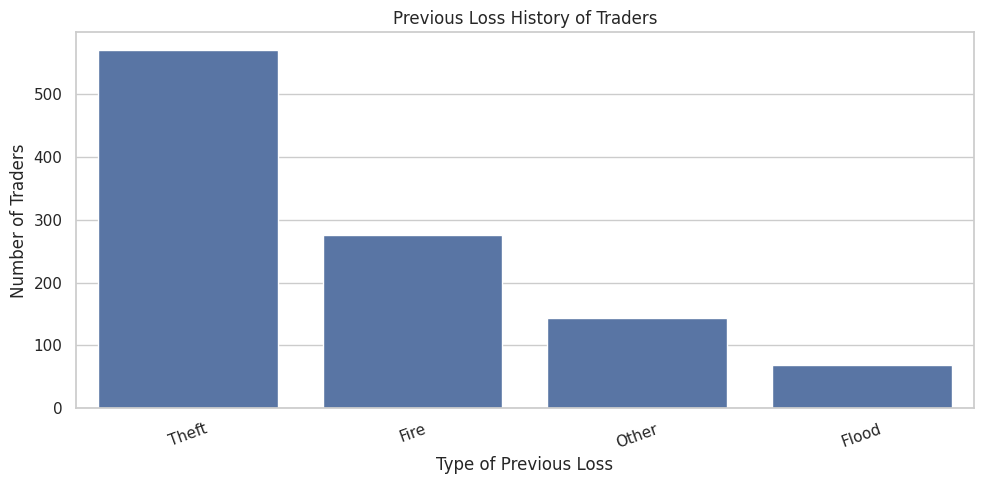


Loss counts:
previous_loss_type
NaN      3942
Theft     570
Fire      276
Other     143
Flood      69
Name: count, dtype: int64

Loss percentages:
previous_loss_type
Theft    53.88
Fire     26.09
Other    13.52
Flood     6.52
Name: proportion, dtype: float64


In [14]:
# Cell 10: Previous loss history

loss_col = "previous_loss_type"

if loss_col in df.columns:

    plt.figure(figsize=(10, 5))

    order = df[loss_col].value_counts().index

    sns.countplot(
        data=df,
        x=loss_col,
        order=order
    )

    plt.title("Previous Loss History of Traders")
    plt.xlabel("Type of Previous Loss")
    plt.ylabel("Number of Traders")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    print("\nLoss counts:")
    print(df[loss_col].value_counts(dropna=False))

    print("\nLoss percentages:")
    print((df[loss_col].value_counts(normalize=True) * 100).round(2))

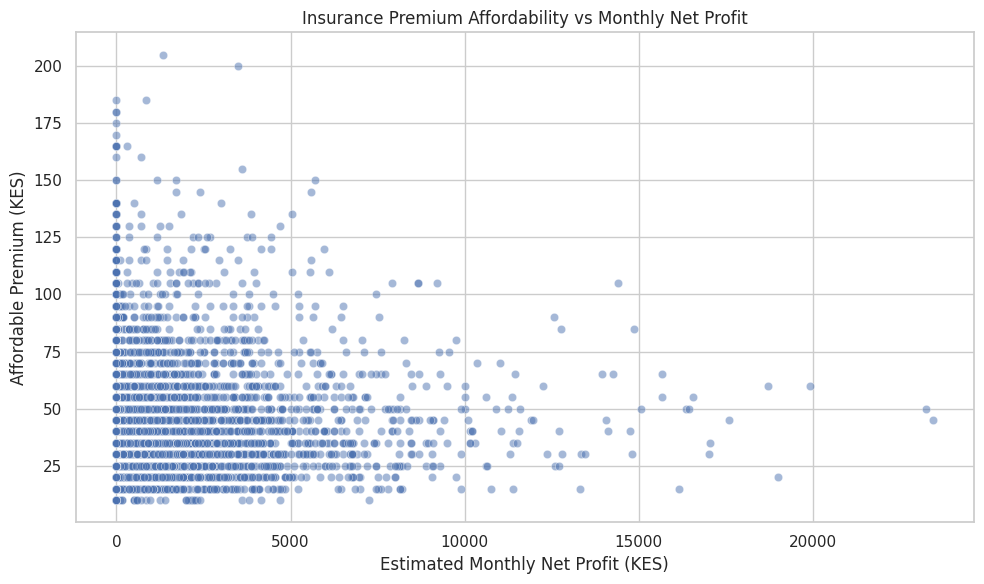

Premium-to-net-profit percentage:
count    2839.00
mean        6.84
std        15.53
min         0.09
25%         1.09
50%         2.35
75%         5.71
max       210.00
Name: premium_to_net_profit_pct, dtype: float64


In [15]:
# Cell 11: Premium affordability analysis

profit_col = "estimated_monthly_net_profit_kes"
premium_col = "affordable_insurance_premium_kes"

if {profit_col, premium_col}.issubset(df.columns):

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=df,
        x=profit_col,
        y=premium_col,
        alpha=0.5
    )

    plt.title("Insurance Premium Affordability vs Monthly Net Profit")
    plt.xlabel("Estimated Monthly Net Profit (KES)")
    plt.ylabel("Affordable Premium (KES)")
    plt.tight_layout()
    plt.show()

    # Optional: premium as a percentage of monthly net profit.
    # This ratio is undefined when net profit is zero.
    df["premium_to_net_profit_pct"] = np.where(
        df[profit_col] > 0,
        (df[premium_col] / df[profit_col]) * 100,
        np.nan
    )

    print("Premium-to-net-profit percentage:")
    print(
        df["premium_to_net_profit_pct"]
        .describe(percentiles=[0.25, 0.50, 0.75])
        .round(2)
    )

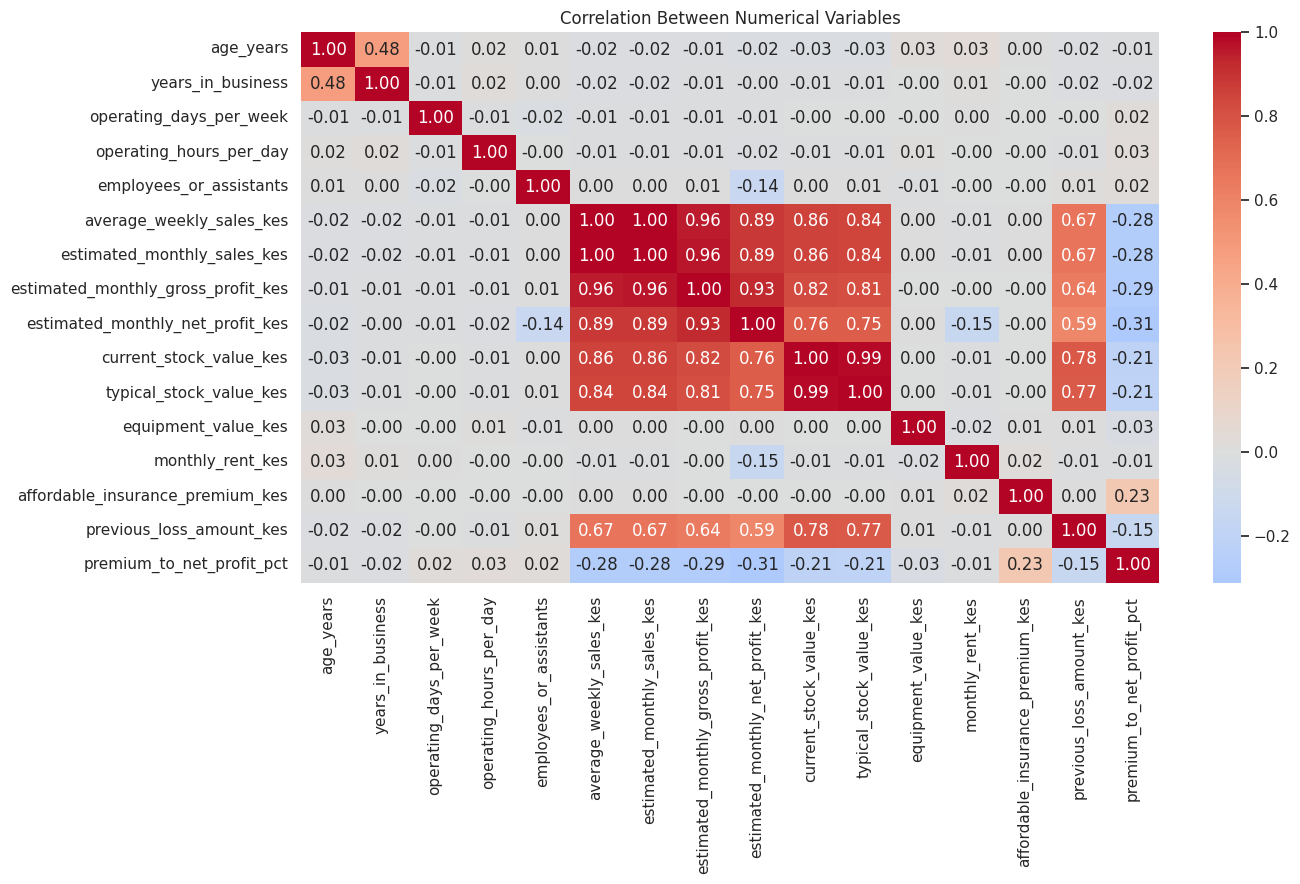

In [16]:
# Cell 12: Correlation analysis

numeric_df = df.select_dtypes(include="number")

if not numeric_df.empty:

    correlation = numeric_df.corr()

    plt.figure(figsize=(14, 9))

    sns.heatmap(
        correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0
    )

    plt.title("Correlation Between Numerical Variables")
    plt.tight_layout()
    plt.show()

In [17]:
# Cell 13: Quick exploratory report

print("=" * 55)
print("RECOVER MICROINSURANCE — EXPLORATORY DATA REPORT")
print("=" * 55)

print(f"\nNumber of records: {len(df):,}")
print(f"Number of columns: {len(df.columns)}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Total missing cells: {df.isnull().sum().sum():,}")

if "age_years" in df.columns:
    print(f"\nAverage age: {df['age_years'].mean():.1f} years")
    print(f"Median age: {df['age_years'].median():.1f} years")

for col in [
    "average_weekly_sales_kes",
    "estimated_monthly_sales_kes",
    "estimated_monthly_net_profit_kes",
    "current_stock_value_kes",
    "monthly_rent_kes",
    "affordable_insurance_premium_kes"
]:
    if col in df.columns:
        print(f"\n{col.replace('_', ' ').title()}")
        print(f"  Median: KSh {df[col].median():,.0f}")
        print(f"  Minimum: KSh {df[col].min():,.0f}")
        print(f"  Maximum: KSh {df[col].max():,.0f}")

if "business_type" in df.columns:
    print("\nBusiness type counts:")
    print(df["business_type"].value_counts())

if "previous_loss_type" in df.columns:
    print("\nPrevious loss counts:")
    print(df["previous_loss_type"].value_counts())

RECOVER MICROINSURANCE — EXPLORATORY DATA REPORT

Number of records: 5,000
Number of columns: 26
Duplicate rows: 0
Total missing cells: 10,045

Average age: 40.9 years
Median age: 40.0 years

Average Weekly Sales Kes
  Median: KSh 2,550
  Minimum: KSh 300
  Maximum: KSh 18,000

Estimated Monthly Sales Kes
  Median: KSh 11,050
  Minimum: KSh 1,300
  Maximum: KSh 77,950

Estimated Monthly Net Profit Kes
  Median: KSh 350
  Minimum: KSh 0
  Maximum: KSh 23,450

Current Stock Value Kes
  Median: KSh 4,900
  Minimum: KSh 500
  Maximum: KSh 57,900

Monthly Rent Kes
  Median: KSh 950
  Minimum: KSh 150
  Maximum: KSh 8,000

Affordable Insurance Premium Kes
  Median: KSh 40
  Minimum: KSh 10
  Maximum: KSh 205

Business type counts:
business_type
Mitumba clothes                   2360
Mixed clothing and accessories    1230
Shoes                              975
Bags                               435
Name: count, dtype: int64

Previous loss counts:
previous_loss_type
Theft    570
Fire     276
O